In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mma3001_project.schedule import (arrival_onset, occupied_mask, schedule_mask,
                                      simulate_temperature, schedule_metrics)
from mma3001_project.thermal import time_to_reach

recon = pd.read_csv("../data/processed/sensor869_reconstructed.csv", index_col=0, parse_dates=True)
events = pd.read_csv("../results/daily_events.csv", index_col=0, parse_dates=True)
inputs = pd.read_csv("../results/schedule_inputs.csv", index_col=0).iloc[:, 0]
temp = recon["temp_c"]
warm = (inputs["warm_T_inf"], inputs["warm_tau_h"])
cool = (inputs["cool_T_inf"], inputs["cool_tau_h"])
print("warm-up:", np.round(warm, 2), " cool-down:", np.round(cool, 2))

warm-up: [24.2   0.77]  cool-down: [21.03  3.88]


In [2]:
onset = arrival_onset(recon["co2_ppm"])
departure = events["departure_h"]
weekday_dates = onset.index[onset.index.dayofweek < 5]
print("Weekday arrival onset (h): p10 %.2f, median %.2f  (found on %d of %d weekdays)"
      % (onset[weekday_dates].quantile(0.1), onset[weekday_dates].median(),
         onset[weekday_dates].count(), len(weekday_dates)))
print("Weekday departure (h): median %.2f, p90 %.2f" % (departure[departure.index.dayofweek < 5].median(),
                                                        departure[departure.index.dayofweek < 5].quantile(0.9)))
print("Weekend days with a clear arrival:", onset[onset.index.dayofweek >= 5].count(), "of",
      (onset.index.dayofweek >= 5).sum())
occupied = occupied_mask(temp.index, onset[weekday_dates], departure)
print("Occupied 10-min slots:", occupied.sum())

Weekday arrival onset (h): p10 8.50, median 9.67  (found on 63 of 77 weekdays)
Weekday departure (h): median 18.33, p90 21.17
Weekend days with a clear arrival: 8 of 30
Occupied 10-min slots: 3025


In [3]:
current = schedule_mask(temp.index, weekday=(7.0, 24.0), weekend=(7.0, 24.0))
T_current = simulate_temperature(current, temp.iloc[0], warm, cool)
err = T_current - temp.to_numpy()
print(f"Simulated vs measured (current schedule): RMSE {np.sqrt(np.mean(err**2)):.2f} °C, bias {err.mean():+.2f} °C")
print(f"Occupied slots below 22.5 °C: measured {100*np.mean(temp.to_numpy()[occupied] < 22.5):.1f}%, "
      f"simulated {100*np.mean(T_current[occupied] < 22.5):.1f}%")

Simulated vs measured (current schedule): RMSE 1.01 °C, bias +0.51 °C
Occupied slots below 22.5 °C: measured 1.6%, simulated 0.2%


In [4]:
def propose(comfort, arrival_q=0.1, departure_q=0.9):
    warm_up = time_to_reach(21.0, comfort, *warm)
    hold = time_to_reach(23.5, comfort, *cool)
    start = np.floor((onset[weekday_dates].quantile(arrival_q) - warm_up) * 6) / 6
    stop = np.ceil((departure[departure.index.dayofweek < 5].quantile(departure_q) - hold) * 6) / 6
    return start, stop

start, stop = propose(comfort=22.5)
print(f"Proposed weekdays: on {int(start):02d}:{round(start%1*60):02d}, off {int(stop):02d}:{round(stop%1*60):02d}; weekends off")

Proposed weekdays: on 08:00, off 19:10; weekends off


In [5]:
proposed = schedule_mask(temp.index, weekday=(start, stop))
T_proposed = simulate_temperature(proposed, temp.iloc[0], warm, cool)
comparison = pd.DataFrame({
    "current (07:00–24:00, 7 days)": schedule_metrics(current, T_current, occupied, 22.5, cool[0]),
    "proposed (weekdays only)": schedule_metrics(proposed, T_proposed, occupied, 22.5, cool[0]),
}).T
comparison.loc["saving [%]"] = 100 * (1 - comparison.iloc[1] / comparison.iloc[0])
comparison.loc["saving [%]", "occupied_below_comfort_pct"] = np.nan
comparison.round(1)

,run_h_per_week,degree_h_per_week,occupied_below_comfort_pct
"current (07:00–24:00, 7 days)",118.9,433.9,0.2
proposed (weekdays only),55.7,224.5,0.9
saving [%],53.1,48.3,NaN


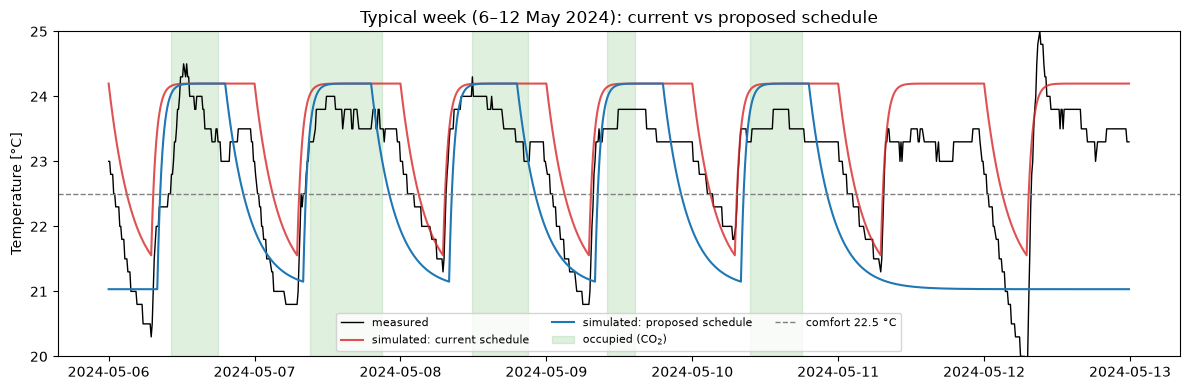

In [6]:
local = temp.index.tz_convert("Australia/Melbourne")
week = (local >= "2024-05-06") & (local < "2024-05-13")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(local[week], temp[week], color="black", lw=1, label="measured")
ax.plot(local[week], T_current[week], color="tab:red", alpha=0.8, label="simulated: current schedule")
ax.plot(local[week], T_proposed[week], color="tab:blue", label="simulated: proposed schedule")
ax.fill_between(local[week], 20, 25, where=occupied[week], color="tab:green", alpha=0.15, label="occupied (CO$_2$)")
ax.axhline(22.5, color="grey", ls="--", lw=1, label="comfort 22.5 °C")
ax.set_ylim(20, 25); ax.set_ylabel("Temperature [°C]"); ax.legend(ncol=3, fontsize=8)
ax.set_title("Typical week (6–12 May 2024): current vs proposed schedule")
plt.tight_layout(); plt.show()

In [7]:
rows = []
for comfort in [22.0, 22.5, 23.0]:
    for q in [0.1, 0.25]:
        s, e = propose(comfort, arrival_q=q)
        on = schedule_mask(temp.index, weekday=(s, e))
        m = schedule_metrics(on, simulate_temperature(on, temp.iloc[0], warm, cool), occupied, comfort, cool[0])
        rows.append({"comfort [°C]": comfort, "arrival quantile": q, "on [h]": s, "off [h]": e, **m})
sensitivity = pd.DataFrame(rows)
sensitivity.round(2)

,comfort [°C],arrival quantile,on [h],off [h],run_h_per_week,degree_h_per_week,occupied_below_comfort_pct
0,22.0,0.10,8.17,17.67,47.32,198.51,0.89
1,22.0,0.25,8.83,17.67,44.00,188.16,2.12
2,22.5,0.10,8.00,19.17,55.72,224.52,0.93
3,22.5,0.25,8.67,19.17,52.40,214.25,2.15
4,23.0,0.10,7.67,20.33,63.26,247.66,0.89
5,23.0,0.25,8.33,20.33,59.94,237.50,2.12


In [8]:
os.makedirs("../results", exist_ok=True)
comparison.to_csv("../results/schedule_comparison.csv")
sensitivity.to_csv("../results/schedule_sensitivity.csv", index=False)